# Session 4 : Collecte de données - Web Scraping et APIs

#### Master TIDE 2026-2027

0. **Rappels**
1. **Web scraping**
2. **API**

&copy; 2026 Francis Wolinski

## 0. Rappels

### Protocoles HTTP / HTTPS

- **HTTP** : *HyperText Transfer Protocol*, protocole permettant au client (navigateur / script) de communiquer avec un serveur web.
- **HTTPS** : *HyperText Transfer Protocol Secure*, version sécurisée de HTTP, chiffrée via TLS (*Transport Layer Security*).

Il existe plusieurs méthodes dont :
- *GET* : envoie une requête pour obtenir une ressource. Les paramètres sont dans l’URL.
- *POST* : envoie des données dans le corps de la requête (formulaires, connexions), plus adapté pour transmettre des informations sensibles ou volumineuses.

Les **entêtes HTTP** (HTTP headers) sont des méta informations envoyées avec chaque requête et réponse HTTP. Elles décrivent le contexte de la communication : informations sur le client (`User-Agent`), type de contenu attendu ou envoyé (`Content-Type`), gestion du cache (`Cache-Control`), token d'authentification (`Authorization`), cookies, encodage, etc. Pour le web scraping, modifier certains entêtes. Par exemple le `User-Agent` permet de se faire reconnaître comme un navigateur classique, tandis qu’en lire d’autres aide à comprendre comment le serveur gère la session ou les données retournées.

```python
{
    "User-Agent": "Mozilla/5.0",
    "Accept": "application/json",
    "Content-Type": "application/json",
    "Authorization": "Bearer my_api_token",
    "Accept-Language": "fr-FR,fr;q=0.9"
}
```

**Documentation** : https://developer.mozilla.org/fr/docs/Web/HTTP

### HTML et balises de base

**HTML** : *HyperText Markup Language*, langage qui structure le contenu d’une page web.

Exemples de tags :
- `<h1>...</h1>` : balises de titre
- `<p>...</p>` : paragraphe de texte.
- `<br />` : retour à la ligne (balise autofermante).

Ces balises constituent la structure que le *web scraper* va analyser pour extraire des données.

**Documentation** : https://developer.mozilla.org/fr/docs/Web/HTML

### CSS

**CSS** : *Cascading Style Sheets*, langage de description de la présentation des documents.

Exemples d'attributs :
- `id` : identifiant unique d’un élément dans une page, utile pour cibler précisément un élément,
- `class` : groupe d’éléments partageant le même style ou comportement,
- `style` : définition directe d’un style sur l’élément.

**Documentation** : https://developer.mozilla.org/fr/docs/Web/CSS

Exemple HTML + CSS :

```html
<p id="1234", class="class1 class2", style="color:blue;font-size:20px;">Exemple de <span style="color:red;font-weight:bold;">paragraphe</span> !</p>
```

En web scraping, les tags et les attributs `id` et `class` servent souvent à sélectionner les bons éléments dans le DOM (*Document Object Model*).

<p id="1234", class="class1 class2", style="color:blue;font-size:20px;">Exemple de <span style="color:red;font-weight:bold;">paragraphe</span> !</p>

## 1. Web Scraping

- Extraction d'informations d'un site web.
- A utiliser en l'absence de données ouvertes ou d'API.
- Technique fragile car le site web peut changer du jour au lendemain.
- Problématique juridique...

**Avec requests et Beautiful Soup**

Documentation :
- **requests** : https://requests.readthedocs.io/en/master/
- **Beautiful Soup** : https://beautiful-soup-4.readthedocs.io/en/latest/

**Beautiful Soup** nécessite la librairie **lxml** qui permet de parser du XML : https://lxml.de/

Pages de test :
- https://kim.fspot.org/cours/page2.html
- https://kim.fspot.org/cours/page3.html

In [1]:
import requests

r = requests.get('https://kim.fspot.org/cours/page2.html')
r.status_code

200

In [2]:
# type
type(r.content)

bytes

In [3]:
r.content

b'\n<!doctype html>\n<html lang="en">\n<head>\n    <meta charset="utf-8">\n    <meta name="viewport" content="width=device-width, initial-scale=1.0">\n    <link rel="stylesheet" href="https://unpkg.com/purecss@1.0.1/build/pure-min.css" integrity="sha384-oAOxQR6DkCoMliIh8yFnu25d7Eq/PHS21PClpwjOTeU2jRSq11vu66rf90/cZr47" crossorigin="anonymous">\n    <link rel="stylesheet" href="https://unpkg.com/purecss@1.0.1/build/grids-responsive-min.css">\n    <link rel="stylesheet" href="page2.css">\n</head>\n<body>\n\n<div class="pure-menu pure-menu-horizontal">\n    <a href="#" class="pure-menu-heading">Your Logo</a>\n    <ul class="pure-menu-list">\n        <li class="pure-menu-item"><a href="#" class="pure-menu-link">Home</a></li>\n        <li class="pure-menu-item pure-menu-selected"><a href="#" class="pure-menu-link">Pricing</a></li>\n        <li class="pure-menu-item"><a href="#" class="pure-menu-link">Contact</a></li>\n    </ul>\n</div>\n\n<div class="banner">\n    <h1 class="banner-head">\n 

In [4]:
# str en précisant un encodage
content = r.content.decode('utf-8')
type(content)

str

In [5]:
content

'\n<!doctype html>\n<html lang="en">\n<head>\n    <meta charset="utf-8">\n    <meta name="viewport" content="width=device-width, initial-scale=1.0">\n    <link rel="stylesheet" href="https://unpkg.com/purecss@1.0.1/build/pure-min.css" integrity="sha384-oAOxQR6DkCoMliIh8yFnu25d7Eq/PHS21PClpwjOTeU2jRSq11vu66rf90/cZr47" crossorigin="anonymous">\n    <link rel="stylesheet" href="https://unpkg.com/purecss@1.0.1/build/grids-responsive-min.css">\n    <link rel="stylesheet" href="page2.css">\n</head>\n<body>\n\n<div class="pure-menu pure-menu-horizontal">\n    <a href="#" class="pure-menu-heading">Your Logo</a>\n    <ul class="pure-menu-list">\n        <li class="pure-menu-item"><a href="#" class="pure-menu-link">Home</a></li>\n        <li class="pure-menu-item pure-menu-selected"><a href="#" class="pure-menu-link">Pricing</a></li>\n        <li class="pure-menu-item"><a href="#" class="pure-menu-link">Contact</a></li>\n    </ul>\n</div>\n\n<div class="banner">\n    <h1 class="banner-head">\n  

In [10]:
#r2 = requests.get('https://www.leboncoin.fr/')
r2 = requests.get('https://www.lacentrale.fr/')
r2.status_code

403

In [11]:
r2.content.decode('utf-8')

'<html lang="en"><head><title>lacentrale.fr</title><style>#cmsg{animation: A 1.5s;}@keyframes A{0%{opacity:0;}99%{opacity:0;}100%{opacity:1;}}</style></head><body style="margin:0"><p id="cmsg">Please enable JS and disable any ad blocker</p><script data-cfasync="false">var dd={\'rt\':\'c\',\'cid\':\'AHrlqAAAAAMASudIYRPRYU8AwTdj8w==\',\'hsh\':\'36C95FCC733A6BF92F5AC434FF65D7\',\'t\':\'bv\',\'qp\':\'\',\'s\':26576,\'e\':\'a52c9e63d500f471cf45420c40b5846e6c8fbf43880fdca2b1d9b2e68ed52fc806eba6ccd7e1e4d54232a0f0d0b6e06b\',\'host\':\'geo.captcha-delivery.com\',\'cookie\':\'J_jRO8iw9KmjbFQHa3gXLSmoUu_~wM9D6oH3~fH810cAm~IyOIXXaIpz1I76bazie2EtM5Nljr_wrbE3~f1Dz4rtk8EL4MTZgBO8ZpwnpKHsXHXGKtkvqwfE_t1WNqRu\'}</script><script data-cfasync="false" src="https://ct.captcha-delivery.com/c.js"></script></body></html>'

In [12]:
# BeautifulSoup

from bs4 import BeautifulSoup

soup = BeautifulSoup(content, "html.parser")
soup


<!DOCTYPE html>

<html lang="en">
<head>
<meta charset="utf-8"/>
<meta content="width=device-width, initial-scale=1.0" name="viewport"/>
<link crossorigin="anonymous" href="https://unpkg.com/purecss@1.0.1/build/pure-min.css" integrity="sha384-oAOxQR6DkCoMliIh8yFnu25d7Eq/PHS21PClpwjOTeU2jRSq11vu66rf90/cZr47" rel="stylesheet"/>
<link href="https://unpkg.com/purecss@1.0.1/build/grids-responsive-min.css" rel="stylesheet"/>
<link href="page2.css" rel="stylesheet"/>
</head>
<body>
<div class="pure-menu pure-menu-horizontal">
<a class="pure-menu-heading" href="#">Your Logo</a>
<ul class="pure-menu-list">
<li class="pure-menu-item"><a class="pure-menu-link" href="#">Home</a></li>
<li class="pure-menu-item pure-menu-selected"><a class="pure-menu-link" href="#">Pricing</a></li>
<li class="pure-menu-item"><a class="pure-menu-link" href="#">Contact</a></li>
</ul>
</div>
<div class="banner">
<h1 class="banner-head">
        Simple Pricing.<br/>
        Try before you buy.
    </h1>
</div>
<div cla

Accès au texte brut

In [13]:
# accès au texte brut
soup.get_text()

'\n\n\n\n\n\n\n\n\n\n\n\nYour Logo\n\nHome\nPricing\nContact\n\n\n\n\n        Simple Pricing.\n        Try before you buy.\n    \n\n\n\n\n\n\nPersonal\n\n                        $5 per month\n\n\n\nFree setup\nCustom sub-domain\nStandard customer support\n1GB file storage\n1 database\nUnlimited bandwidth\n\nChoose\n\n\n\n\n\nSmall Business\n\n                        $25 per month\n\n\n\nFree setup\nUse your own domain\nStandard customer support\n10GB file storage\n5 databases\nUnlimited bandwidth\n\nChoose\n\n\n\n\n\nEnterprise\n\n                        $45 per month\n\n\n\nFree setup\nUse your own domain\nPremium customer support\n100GB file storage\n25 databases\nUnlimited bandwidth\n\nChoose\n\n\n \n\n\n\nGet started today\n\n                    Lorem ipsum dolor sit amet, consectetur adipisicing elit, sed do eiusmod tempor incididunt ut labore et dolore magna aliqua. Lorem ipsum dolor sit amet, consectetur adipisicing elit, sed do eiusmod tempor incididunt ut labore et dolore magn

Pour extraire des éléments particuliers, on utilise différentes méthodes :
    
- `.find(tag, attrs)` : trouve le premier tag avec les attributs spécifiés (en général `id` et/ou `class`)
- `.findAll(tag, attrs)` : trouve tous les tags avec les attributs spécifiés (en général `id` et/ou `class`)
- `.select(css)` : trouve tous les tags avec les CSS spécifiées
- etc.

La technique consiste par exemple à alimenter un dictionnaire avec les valeurs trouvées :
- soit en utilisant `tag.attrs['attribut']` pour collecter la valeur `'attribut'` du tag
- soit en utilisant `tag.text` pour collecter la valeur `text` située entre les balises ouvrante et fermante,
- on peut aussi utiliser d'autres méthodes comme `.select()` qui joue sur la CSS ou `.next_sibling()` pour collecter le tag identique suivant,
- éventuellement en recherchant dans un nouveau tag à l'intérieur d'un tag donné,
- parfois, il faut tester si la méthode `.find()` retourne bien un élément ou `None`.

In [14]:
# exploration du HTML

div_tag = soup.find('div', attrs={'class': 'pricing-table'})
div_tag

<div class="pricing-table pricing-table-free">
<div class="pricing-table-header">
<h2>Personal</h2>
<span class="pricing-table-price">
                        $5 <span>per month</span>
</span>
</div>
<ul class="pricing-table-list">
<li>Free setup</li>
<li>Custom sub-domain</li>
<li>Standard customer support</li>
<li>1GB file storage</li>
<li>1 database</li>
<li>Unlimited bandwidth</li>
</ul>
<button class="button-choose pure-button">Choose</button>
</div>

Méthode :
 1. On collecte les informations d'un  tag pour un seul enregistrement sous la forme d'un dictionaire.
 2. On généralise en bouclant sur tous les tags de même nature et on rassemble les dictionnaires dans une liste.
 3. On transforme ensuite la liste de dictionaires en DataFrame.

In [15]:
# 1. collecte des informations pour un enregistrement
row = {}

div_tag = soup.find('div', attrs={'class': 'pricing-table'})

# type : Personal, Small Business, Enterprise
h2_tag = div_tag.find("h2")
row["type"] = h2_tag.text

# price
span_tag = div_tag.find("span", attrs={'class': 'pricing-table-price'})
row["price"] = span_tag.text.strip().split()[0]

# storage, database
lis = div_tag.select("li")
row["storage"] = lis[3].text.split()[0]
row["database"] = lis[4].text.split()[0]

row

{'type': 'Personal', 'price': '$5', 'storage': '1GB', 'database': '1'}

In [16]:
# 2. collecte des informations pour tous les enregistrements
rows = []

for div_tag in soup.find_all('div', attrs={'class': 'pricing-table'}):
    row = {}
    
    # type : Personal, Small Business, Enterprise
    h2_tag = div_tag.find("h2")
    row["type"] = h2_tag.text
    
    # price
    span_tag = div_tag.find("span", attrs={'class': 'pricing-table-price'})
    row["price"] = span_tag.text.strip().split()[0]
    
    # storage, database
    lis = div_tag.select("li")
    row["storage"] = lis[3].text.split()[0]
    row["database"] = lis[4].text.split()[0]
    
    rows.append(row)

rows

[{'type': 'Personal', 'price': '$5', 'storage': '1GB', 'database': '1'},
 {'type': 'Small Business',
  'price': '$25',
  'storage': '10GB',
  'database': '5'},
 {'type': 'Enterprise', 'price': '$45', 'storage': '100GB', 'database': '25'}]

In [17]:
# 3. transformation en DataFrame
import pandas as pd
df = pd.DataFrame(rows)
df

,type,price,storage,database
0,Personal,$5,1GB,1
1,Small Business,$25,10GB,5
2,Enterprise,$45,100GB,25


In [18]:
# avec une fonction
def get_product_info(div_tag):
    row = {}

    # type : Personal, Small Business, Enterprise
    h2_tag = div_tag.find("h2")
    row["type"] = h2_tag.text

    # price
    span_tag = div_tag.find("span", attrs={'class': 'pricing-table-price'})
    row["price"] = span_tag.text.strip().split()[0]

    # storage, database
    lis = div_tag.select("li")
    row["storage"] = lis[3].text.split()[0]
    row["database"] = lis[4].text.split()[0]
    
    return row

def extract_products(url):
    try:
        r = requests.get(url)
        
    except requests.exceptions.RequestException as e:
        print(e)
        return

    # Soup
    soup = BeautifulSoup(r.content, "html.parser")

    # list comprehension with all results
    rows = [get_product_info(div_tag) for div_tag in soup.find_all('div', attrs={'class': 'pricing-table'})]

    # DataFrame with all results
    df = pd.DataFrame(rows)
    
    return df

df = extract_products('https://kim.fspot.org/cours/page2.html')
df

,type,price,storage,database
0,Personal,$5,1GB,1
1,Small Business,$25,10GB,5
2,Enterprise,$45,100GB,25


**Exercices**

- Remplacer la méthode `.find_all()` par la méthode `.select()`
- Web scrapping de la page : https://kim.fspot.org/cours/page3.html
- Web scrapping de la page : https://books.toscrape.com/catalogue/category/books/travel_2/index.html

In [19]:
df = extract_products('https://kim.fspot.org/cours/page3.html')
df

,type,price,storage,database
0,Personal,$5,1GB,1
1,Small Business,$25,10GB,5
2,Enterprise,$45,100GB,25
3,Privilege,$99,1TB,100


In [21]:
df.values

array([['Personal', '$5', '1GB', '1'],
       ['Small Business', '$25', '10GB', '5'],
       ['Enterprise', '$45', '100GB', '25'],
       ['Privilege', '$99', '1TB', '100']], dtype=object)

In [26]:
df["price"].apply(lambda x: int(x[1:]))

0     5
1    25
2    45
3    99
Name: price, dtype: int64

In [27]:
df["storage"].apply(lambda x: int(x[:-2]))

0      1
1     10
2    100
3      1
Name: storage, dtype: int64

In [28]:
df["storage"].apply(lambda x: x[-2:])

0    GB
1    GB
2    GB
3    TB
Name: storage, dtype: str

In [29]:
df["database"].apply(lambda x: int(x))

0      1
1      5
2     25
3    100
Name: database, dtype: int64

In [30]:
def process_storage(storage):
    unit = storage[-2:]  # GB ou TB
    value = int(storage[:-2])
    return value * 1000 if unit == "TB" else value

In [31]:
df["storage"].apply(process_storage)

0       1
1      10
2     100
3    1000
Name: storage, dtype: int64

#### Inconvénients du web scraping:
- Plutôt lent et consommateur de ressources (car on parse potentiellement beaucoup de HTML inutile)
- Ne donne pas les résultats attendus si une partie du contenu est intégré dynamiquement à la page via javascript
- Un changement dans l'architecture du HTML ou du CSS (e.g: refonte du design du site) oblige à réécrire entièrement le programme

## 2. API

Exemple : Deezer

Artiste : https://www.deezer.com/fr/artist/3037

Récupérer le nombre de fans d'un artiste avec requests (cherchez le tag div avec l'id `"naboo_artist_social_small"`).

In [35]:
# request
artist = 3037
# artist = 1479842  # PLK
response = requests.get(f'https://www.deezer.com/fr/artist/{artist}')
print(f"{len(response.content):,.0f} bytes")

1,417,883 bytes


In [33]:
!python --version

Python 3.13.3


In [34]:
requests.__version__

'2.34.2'

In [36]:
soup = BeautifulSoup(response.content)
n = soup.find("div", attrs={"id": "naboo_artist_social_small"}).find("span").text
print(f"{int(n):,.0f} fans")

1,203,936 fans


Le terme "API" est très générique et peut désigner bien des choses, mais dans le jargon on l'utilise souvent pour désigner un service web qui renvoie non pas:
> des pages web au format HTML (destinées à être lues par un humain dans son navigateur)

mais:
> des données au format JSON (ou texte, ou XML, destinées à être traitées par un programme)

![img](https://miro.medium.com/max/4238/1*OcmVkcsM5BWRHrg8GC17iw.png)

Puisque les API sont dédiées à l'usage via des programmes, elles disposent en général d'une bonne documentation, et sont fiables et stables dans le temps. Tandis que sur des pages web HTML classiques, le design peut par exemple changer du jour au lendemain et rendre votre programme Beautiful Soup obsolète.

In [37]:
# API JSON
response = requests.get(f'https://api.deezer.com/artist/{artist}')
response.content

b'{"id":3037,"name":"Genesis","link":"https:\\/\\/www.deezer.com\\/artist\\/3037","share":"https:\\/\\/www.deezer.com\\/artist\\/3037?utm_source=deezer&utm_content=artist-3037&utm_term=0_1795010760&utm_medium=web","picture":"https:\\/\\/api.deezer.com\\/artist\\/3037\\/image","picture_small":"https:\\/\\/cdn-images.dzcdn.net\\/images\\/artist\\/c0ed2cf09c7bf072111d614fc4557b66\\/56x56-000000-80-0-0.jpg","picture_medium":"https:\\/\\/cdn-images.dzcdn.net\\/images\\/artist\\/c0ed2cf09c7bf072111d614fc4557b66\\/250x250-000000-80-0-0.jpg","picture_big":"https:\\/\\/cdn-images.dzcdn.net\\/images\\/artist\\/c0ed2cf09c7bf072111d614fc4557b66\\/500x500-000000-80-0-0.jpg","picture_xl":"https:\\/\\/cdn-images.dzcdn.net\\/images\\/artist\\/c0ed2cf09c7bf072111d614fc4557b66\\/1000x1000-000000-80-0-0.jpg","nb_album":43,"nb_fan":1203936,"radio":true,"tracklist":"https:\\/\\/api.deezer.com\\/artist\\/3037\\/top?limit=50","type":"artist"}'

In [38]:
# taille
print(f"{len(response.content):,.0f} bytes")

889 bytes


In [40]:
889*100/1417883

0.06269910845958376

In [41]:
# json
data = response.json()
data

{'id': 3037,
 'name': 'Genesis',
 'link': 'https://www.deezer.com/artist/3037',
 'share': 'https://www.deezer.com/artist/3037?utm_source=deezer&utm_content=artist-3037&utm_term=0_1795010760&utm_medium=web',
 'picture': 'https://api.deezer.com/artist/3037/image',
 'picture_small': 'https://cdn-images.dzcdn.net/images/artist/c0ed2cf09c7bf072111d614fc4557b66/56x56-000000-80-0-0.jpg',
 'picture_medium': 'https://cdn-images.dzcdn.net/images/artist/c0ed2cf09c7bf072111d614fc4557b66/250x250-000000-80-0-0.jpg',
 'picture_big': 'https://cdn-images.dzcdn.net/images/artist/c0ed2cf09c7bf072111d614fc4557b66/500x500-000000-80-0-0.jpg',
 'picture_xl': 'https://cdn-images.dzcdn.net/images/artist/c0ed2cf09c7bf072111d614fc4557b66/1000x1000-000000-80-0-0.jpg',
 'nb_album': 43,
 'nb_fan': 1203936,
 'radio': True,
 'tracklist': 'https://api.deezer.com/artist/3037/top?limit=50',
 'type': 'artist'}

In [42]:
# nb_fan
print(f"{data['nb_fan']:,.0f} fans")

1,203,936 fans


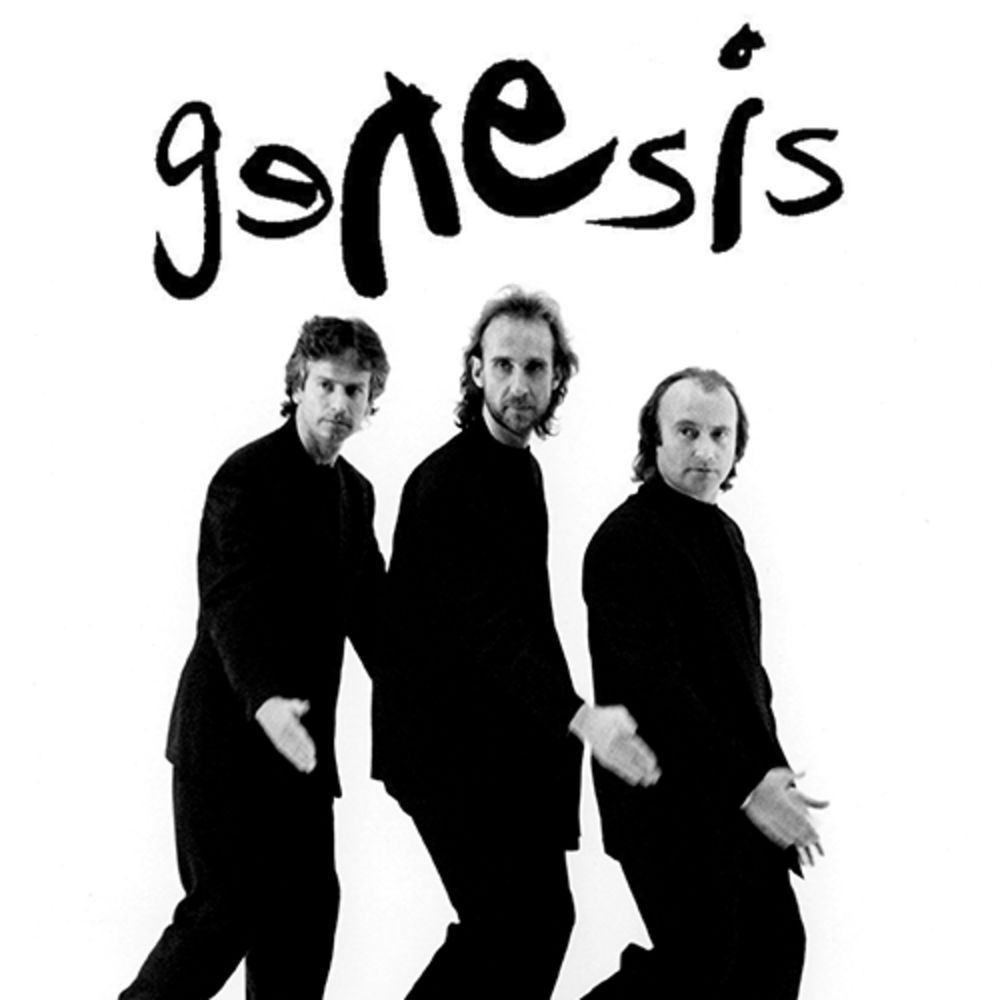

In [44]:
# picture
from IPython import display

url = data['picture_xl']
r = requests.get(url)
display.Image(data=r.content)

In [45]:
# tracklist
url = data["tracklist"]
r = requests.get(url)
dico = r.json()
dico["data"][0]

{'id': 14637544,
 'readable': True,
 'title': "I Can't Dance",
 'title_short': "I Can't Dance",
 'title_version': '',
 'link': 'https://www.deezer.com/track/14637544',
 'duration': 240,
 'rank': 821581,
 'explicit_lyrics': False,
 'explicit_content_lyrics': 6,
 'explicit_content_cover': 2,
 'preview': 'https://cdnt-preview.dzcdn.net/api/1/1/3/e/5/0/3e58a0b5f4f011e8884101b98d0dcfbc.mp3?hdnea=exp=1795011914~acl=/api/1/1/3/e/5/0/3e58a0b5f4f011e8884101b98d0dcfbc.mp3*~data=user_id=0,application_id=42~hmac=a952fd825520bfed3bf81df1aac70e30cd9a1ef7e2fb55a5fd9895710d4e5b76',
 'contributors': [{'id': 3037,
   'name': 'Genesis',
   'link': 'https://www.deezer.com/artist/3037',
   'share': 'https://www.deezer.com/artist/3037?utm_source=deezer&utm_content=artist-3037&utm_term=0_1795011014&utm_medium=web',
   'picture': 'https://api.deezer.com/artist/3037/image',
   'picture_small': 'https://cdn-images.dzcdn.net/images/artist/c0ed2cf09c7bf072111d614fc4557b66/56x56-000000-80-0-0.jpg',
   'picture_med

In [49]:
url = dico["data"][0]["preview"]
display.Video(data=url)

**Exercice**

- Récupérer la liste des titres avec une list comprehension,
- Jouer un morceau à partir du titre avec `IPython.display.Video()`

In [52]:
pd.DataFrame(dico["data"]).head()

,id,readable,title,title_short,title_version,link,duration,rank,explicit_lyrics,explicit_content_lyrics,explicit_content_cover,preview,contributors,md5_image,artist,album,type
0,14637544,True,I Can't Dance,I Can't Dance,,https://www.deezer.com/track/14637544,240,821581,False,6,2,https://cdnt-preview.dzcdn.net/api/1/1/3/e/5/0...,"[{'id': 3037, 'name': 'Genesis', 'link': 'http...",ade41e71897cafc574156046b9633c14,"{'id': 3037, 'name': 'Genesis', 'tracklist': '...","{'id': 1347472, 'title': 'I Can't Dance / On t...",track
1,14639815,True,Jesus He Knows Me (2007 Remaster),Jesus He Knows Me,(2007 Remaster),https://www.deezer.com/track/14639815,256,794052,False,6,2,https://cdnt-preview.dzcdn.net/api/1/1/3/c/0/0...,"[{'id': 3037, 'name': 'Genesis', 'link': 'http...",8968f10c0e11ba7280a44958bda37820,"{'id': 3037, 'name': 'Genesis', 'tracklist': '...","{'id': 1347734, 'title': 'We Can't Dance (2007...",track
2,14638221,True,That's All (Platinum Collection Version),That's All,(Platinum Collection Version),https://www.deezer.com/track/14638221,265,785379,False,6,2,https://cdnt-preview.dzcdn.net/api/1/1/2/c/d/0...,"[{'id': 3037, 'name': 'Genesis', 'link': 'http...",4ce121328888d3d49fec4edd5e524f17,"{'id': 3037, 'name': 'Genesis', 'tracklist': '...","{'id': 1347551, 'title': 'Platinum Collection'...",track
3,14639826,True,Mama (2007 Remaster),Mama,(2007 Remaster),https://www.deezer.com/track/14639826,410,742008,False,6,2,https://cdnt-preview.dzcdn.net/api/1/1/7/8/5/0...,"[{'id': 3037, 'name': 'Genesis', 'link': 'http...",f69bc45cd6e45319afb11a5258d91e69,"{'id': 3037, 'name': 'Genesis', 'tracklist': '...","{'id': 1347735, 'title': 'Genesis (2007 Remast...",track
4,14637100,True,Invisible Touch (2007 Remaster),Invisible Touch,(2007 Remaster),https://www.deezer.com/track/14637100,208,726116,False,6,2,https://cdnt-preview.dzcdn.net/api/1/1/0/e/1/0...,"[{'id': 3037, 'name': 'Genesis', 'link': 'http...",fe34d9731f608634324ad239cabaae30,"{'id': 3037, 'name': 'Genesis', 'tracklist': '...","{'id': 1347441, 'title': 'Invisible Touch (200...",track


In [53]:
titles = [d["title"] for d in dico["data"]]
titles

["I Can't Dance",
 'Jesus He Knows Me (2007 Remaster)',
 "That's All (Platinum Collection Version)",
 'Mama (2007 Remaster)',
 'Invisible Touch (2007 Remaster)',
 'Hold on My Heart (Platinum Collection Version)',
 'Invisible Touch (Platinum Collection Version)',
 'Abacab (2007 Remaster)',
 'No Son of Mine (2007 Remaster)',
 'In Too Deep (Platinum Collection Version)',
 "That's All (2007 Remaster)",
 'Land of Confusion (2007 Remaster)',
 'Home by the Sea (2007 Remaster)',
 'Land of Confusion (Platinum Collection Version)',
 'Follow You Follow Me (2007 Remaster)',
 'No Son of Mine (Platinum Collection Version)',
 'Firth of Fifth (2007 Stereo Mix)',
 'Tell Me Why (2007 Remaster)',
 'In Too Deep (2007 Remaster)',
 'Dancing with the Moonlit Knight (2007 Stereo Mix)',
 'The Musical Box (2007 Stereo Mix)',
 'Entangled (2007 Remaster)',
 'Throwing It All Away (2007 Remaster)',
 'Turn It on Again (2007 Remaster)',
 'Home by the Sea (Platinum Collection Version)',
 'Second Home by the Sea (2007 

In [56]:
def play(title):
    for d in dico["data"]:
        if d["title"] == title:
            return display.Video(data=d["preview"])

In [57]:
play("Jesus He Knows Me (2007 Remaster)")

#### Avantages d'une API
- Renvoie du format JSON, (ou texte ou XML), facile et rapide à traiter
- Renvoie un format stable et documenté (voire versionné)
- Exemple : https://github.com/bluesky-social/atproto
- La documentation indique comment interagir avec l'API :
    - quelle URL utiliser,
    - quelle méthode HTTP (GET, POST, ...),
    - quels paramètres utiliser,
    - ...

=> Idéal pour les développeurs

### Quel intérêt pour le fournisseur d'API ?

En général, il met en place des quotas de requêtes ou d'autres limitations afin de proposer un service payant qui dispose de possibilités avancées, d'un meilleur support, etc.

C'est pourquoi de nombreux services nécessitent de se connecter avec son compte client pour utiliser une API (e.g. https://openweathermap.org/api).

#### Basic Auth

Exemple: accéder à https://kim.fspot.org/private/

Pour y accéder il est nécessaire d'utiliser les credentials suivants :
- *login* : `'admin'`
- *password* : `'secret'`

Si on ne les passe pas (ou si on ne passe pas les bons), on a obtient une erreur 401 (= unauthorized).

In [58]:
# sans login/password
res = requests.get('https://kim.fspot.org/private/')
res

<Response [401]>

In [59]:
# avec login password
res = requests.get('https://kim.fspot.org/private/', auth=('admin', 'secret'))
res

<Response [200]>

In [60]:
# contenu
res.content.decode('utf-8')

'<!doctype html>\n<html>\n<head>\n<title>Success</title>\n</head>\n<body>\n\t<h1>Well done!</h1>\n</body>\n</html>\n'

<p style="color:red;">Attention, ne pas mettre les credentials dans le code !</p>

Exemple avec la librairie **dotenv**.

```bash
pip install python-dotenv
```

La librairie peut gérer les variables d'environnement et également parser des fichiers de type `.env`.

```txt
username=admin
password=secret
```

In [ ]:
#!pip install python-dotenv

In [61]:
# .env pour masquer auth credentials
# fichier .env avec les credentials

from dotenv import dotenv_values

config = dotenv_values(".env0")  # ici .env0

requests.get('https://kim.fspot.org/private/', auth=(config['username'], config['password']))

<Response [200]>

In [62]:
config

OrderedDict([('username', 'admin'), ('password', 'secret')])

#### Auth par token

Exemple sur le site OpenWeatherMap :
- documentation : https://openweathermap.org/appid
- mes tokens : https://home.openweathermap.org/api_keys

In [63]:
# requête avec un token
config = dotenv_values(".env")
token = config["owm_token"]
n = 4
print(f"{token[:n]}{"x"*(len(token)-2*n)}{token[-n:]}")

d93fxxxxxxxxxxxxxxxxxxxxxxxx99fa


Avantage d'un token :
- Il évite que les requêtes HTTP contiennent le mot de passe - à la place elles contiennent un token,
- Si je me fais "voler" un token, je peux le supprimer de mon compte et en créer un nouveau.

In [64]:
# requête avec un token
ville="Paris"
url = f"http://api.openweathermap.org/data/2.5/weather?APPID={token}&q={ville}"
res = requests.get(url)
meteo = res.json()
meteo

{'coord': {'lon': 2.3488, 'lat': 48.8534},
 'weather': [{'id': 803,
   'main': 'Clouds',
   'description': 'broken clouds',
   'icon': '04d'}],
 'base': 'stations',
 'main': {'temp': 287.66,
  'feels_like': 286.86,
  'temp_min': 286.6,
  'temp_max': 288.58,
  'pressure': 995,
  'humidity': 65,
  'sea_level': 995,
  'grnd_level': 986},
 'visibility': 10000,
 'wind': {'speed': 8.23, 'deg': 250, 'gust': 13.38},
 'clouds': {'all': 75},
 'dt': 1795012086,
 'sys': {'type': 2,
  'id': 2012208,
  'country': 'FR',
  'sunrise': 1794985442,
  'sunset': 1795018063},
 'timezone': 3600,
 'id': 2988507,
 'name': 'Paris',
 'cod': 200}

In [65]:
# type
type(meteo)

dict

In [69]:
# extractions
{'city': meteo['name'],
'country': meteo['sys']['country'],
'date': meteo['dt'],
'temp': meteo['main']['temp'],
'sea_level': meteo['main']['sea_level'],}

{'city': 'Paris',
 'country': 'FR',
 'date': 1795012086,
 'temp': 287.66,
 'sea_level': 995}

In [70]:
# extractions
import time
from scipy.constants import zero_Celsius, foot

print(foot)

{'city': meteo['name'],
'country': meteo['sys']['country'],
'date': time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(meteo['dt'])),
'temp': f"{meteo['main']['temp'] - zero_Celsius:.1f}",
'sea_level': meteo['main']['sea_level']*foot}

0.30479999999999996


{'city': 'Paris',
 'country': 'FR',
 'date': '2026-11-18 15:28:06',
 'temp': '14.5',
 'sea_level': 303.27599999999995}

## API pour les LLMs et le JEV (démos)

Exemples d'utilisation avec **ollama** : https://github.com/ollama/ollama-python

Nécessite l'installation de la librairie **ollama** et le chargement d'un modèle disponible : https://ollama.com/

### LLM

Modèle utilisé : *llama3.2*

Voir les exemples :
- `improve_resume1.py` : appel explicite de l'API avec la librairie **requests**
- `improve_resume2.py` : appel implicite de l'API avec la librairie **ollama**

### JEV

Voir : https://medium.com/@unicodeveloper/the-ultimate-guide-to-jev-the-new-frontier-ai-for-faster-decisions-acd78e5f4c56

Modèle utilisé : *tev1:0.8b*

Voir l'exemple :
- `job_triage.py` : appel implicite de l'API avec la librairie **typesafe_sdk**

### Autres idées de projets

Se créer un compte sur **BlueSky** et requêter des posts.

Nécessite d'installer la librairie **atproto**.

**Documentation** : https://atproto.blue/

#### Rechercher des posts et ensuite faire du NLP sur les textes des posts

Exemples de librairies de NLP :
- **NLTK** : boîte à outils pédagogique et historique pour le TAL (tokenisation, lemmatisation, étiquetage grammatical, corpus, WordNet)
- **gensim** : spécialisée dans la modélisation de sujets (LDA) et les plongements de mots (Word2Vec, FastText, Doc2Vec) sur de gros corpus
- **spaCy** : bibliothèque rapide et prête pour la production, avec pipelines de tokenisation, lemmatisation, étiquetage grammatical, analyse syntaxique et reconnaissance d’entités nommées (NER)
- **scikit-learn** (TF-IDF) : fournit `TfidfVectorizer` et `CountVectorizer` pour transformer des textes en vecteurs numériques, utilisables ensuite pour la classification, le clustering ou la similarité
- **wordcloud** : génère des nuages de mots visuels à partir d’un texte ou de fréquences, sans analyse linguistique

#### Rechercher les followers et ensuite faire des graphes sur les followers

Utiliser **NetworkX** pour la gestion des graphes : https://networkx.org/en/